# Removing Missing Values 

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('data_science_job.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  18679 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  float64
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  training_hours          18392 non-null  float64
 12  target                  19158 non-null  float64
dtypes: float64(4), int64(1), object(8)
memory usage: 1.9+ MB


In [9]:
df.sample()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
17950,5918,city_165,0.903,NaN,No relevent experience,NaN,NaN,NaN,0.0,NaN,NaN,84.0,0.0


In [10]:
(7982/8807)*100

90.63245145906666

In [14]:
missing_cols = [x for x in df.columns if df[x].isnull().mean()<0.05 and df[x].isnull().mean()>0]
missing_cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [17]:
df[missing_cols].isnull().mean()*100

city_development_index    2.500261
enrolled_university       2.014824
education_level           2.401086
experience                0.339284
training_hours            3.998330
dtype: float64

In [18]:
max(df[missing_cols].isnull().count())

19158

In [19]:
new_df = df[missing_cols].dropna()

In [20]:
df.shape, new_df.shape

((19158, 13), (17182, 5))

<Figure size 1200x600 with 0 Axes>

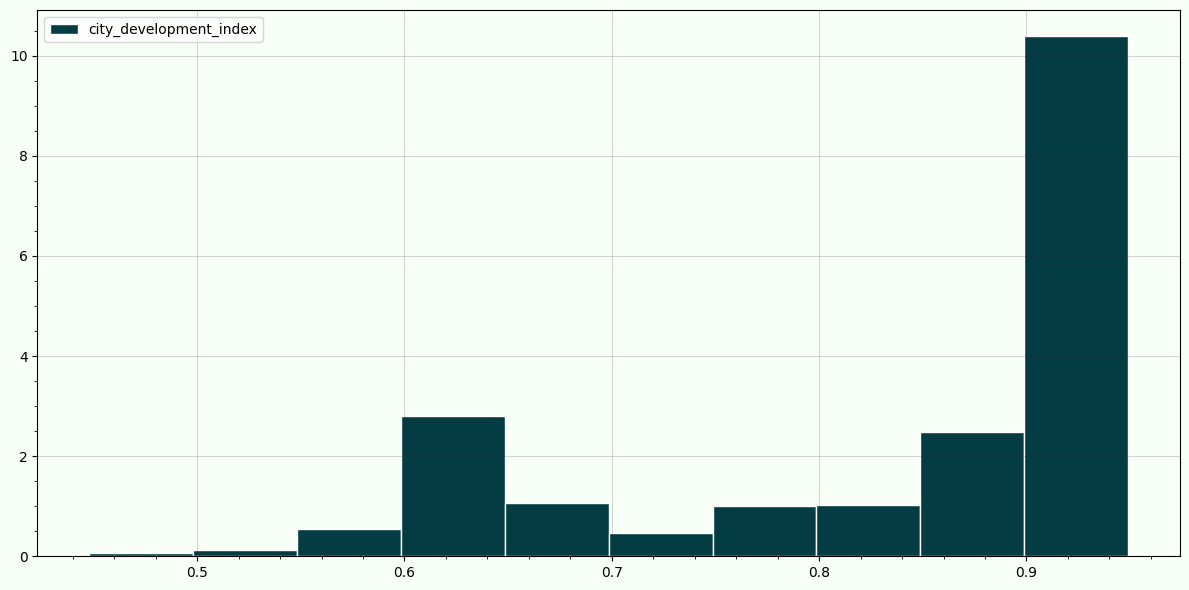

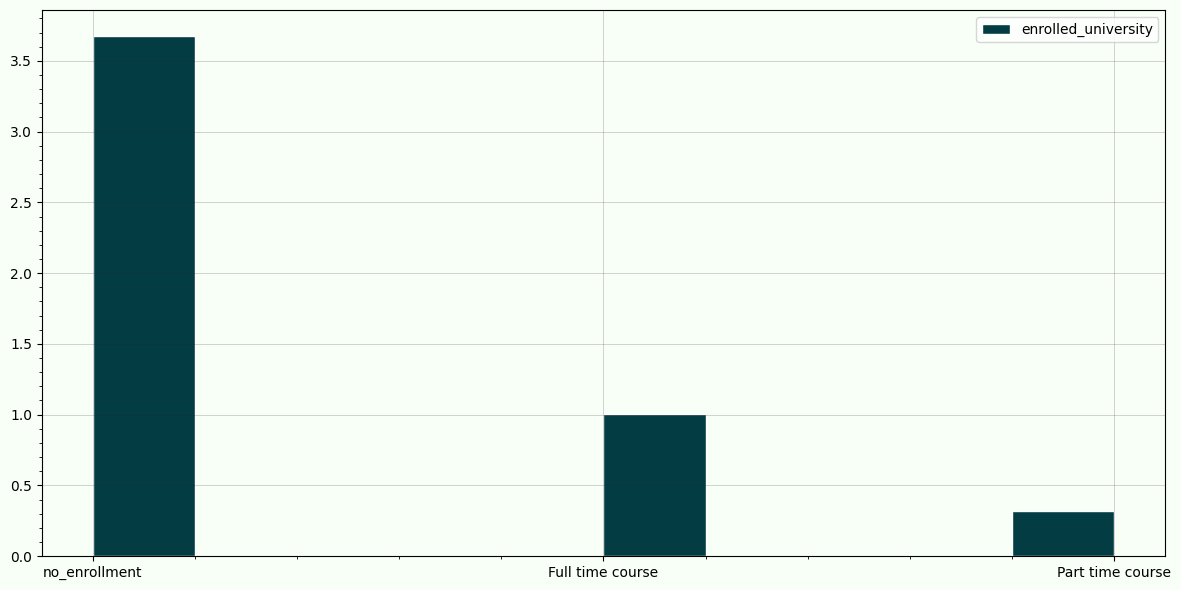

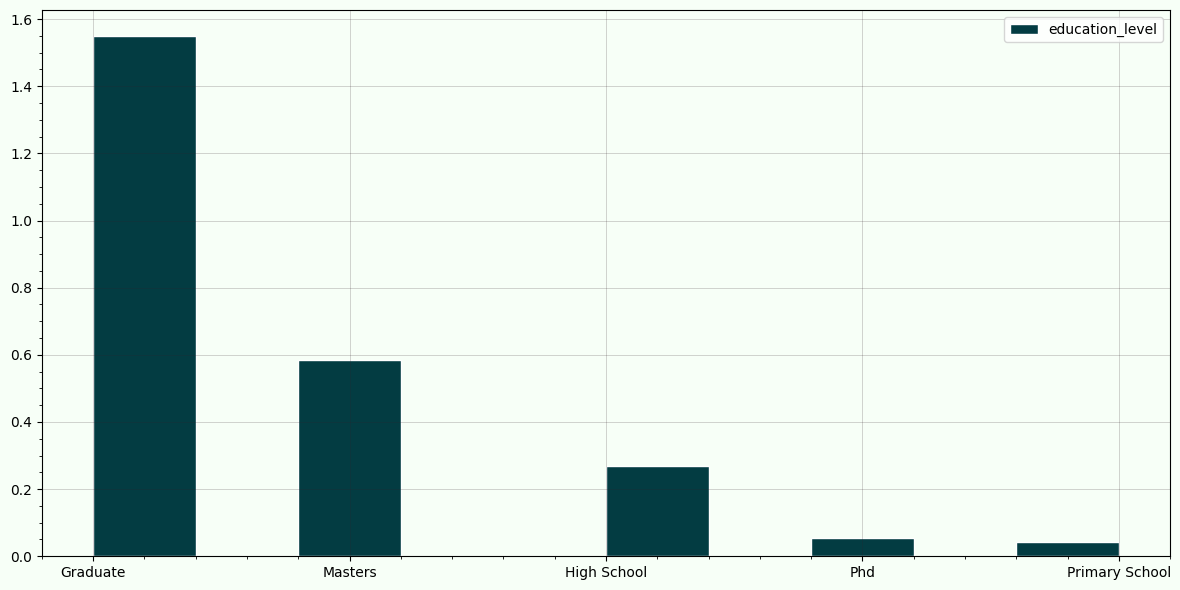

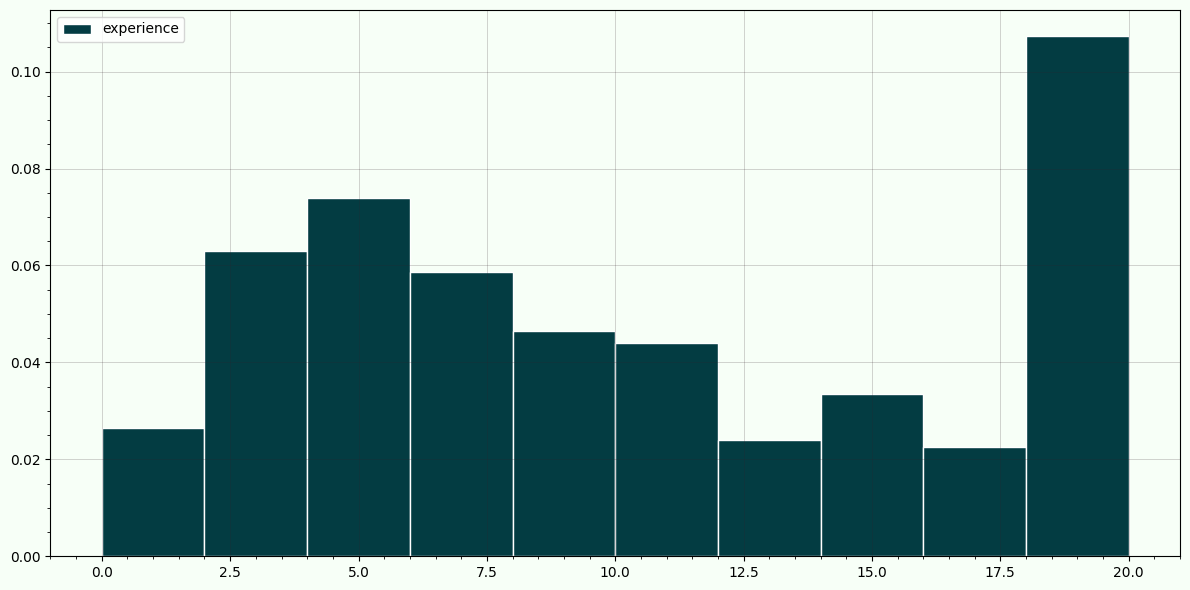

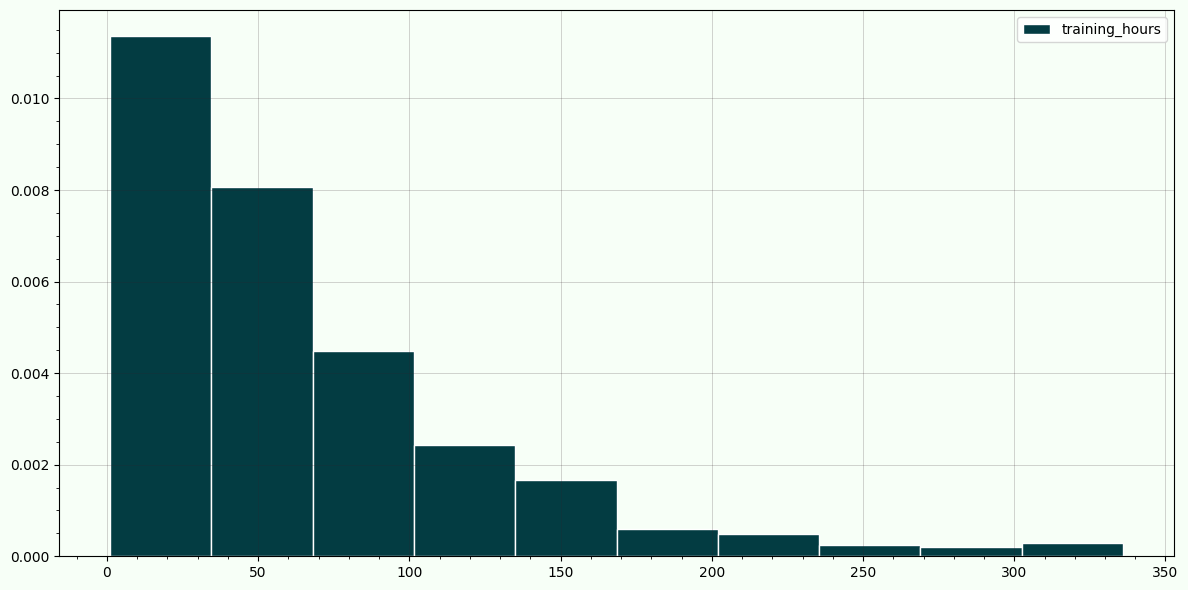

In [113]:
# 1. Set the figure size FIRST

plt.figure(figsize=(12, 6))
for col in new_df.columns:
    bg_color = '#f7fff7'   # medium-dark shade related to #c07c82
    grid_color = '#33202a' # light grid for contrast
    
    plt.figure(figsize=(12, 6))
    ax = plt.gca()

# Set background colors
    ax.set_facecolor(bg_color)       # axes background
    plt.gcf().set_facecolor(bg_color)  # figure background (optional)
    # 2. Create the histogram (without figsize)
    plt.hist(new_df[col], density=True, edgecolor = 'white', color='#033c42', label = col, )
    # Add grid
    ax.grid(
        True,
              # major and minor
       
        linewidth=0.7,
        color=grid_color,
        alpha=0.2,
    )
    
    # Optional: minor ticks for nicer grid
    ax.minorticks_on()
    plt.legend()
    plt.tight_layout()
    # 3. Display the plot
    plt.show()

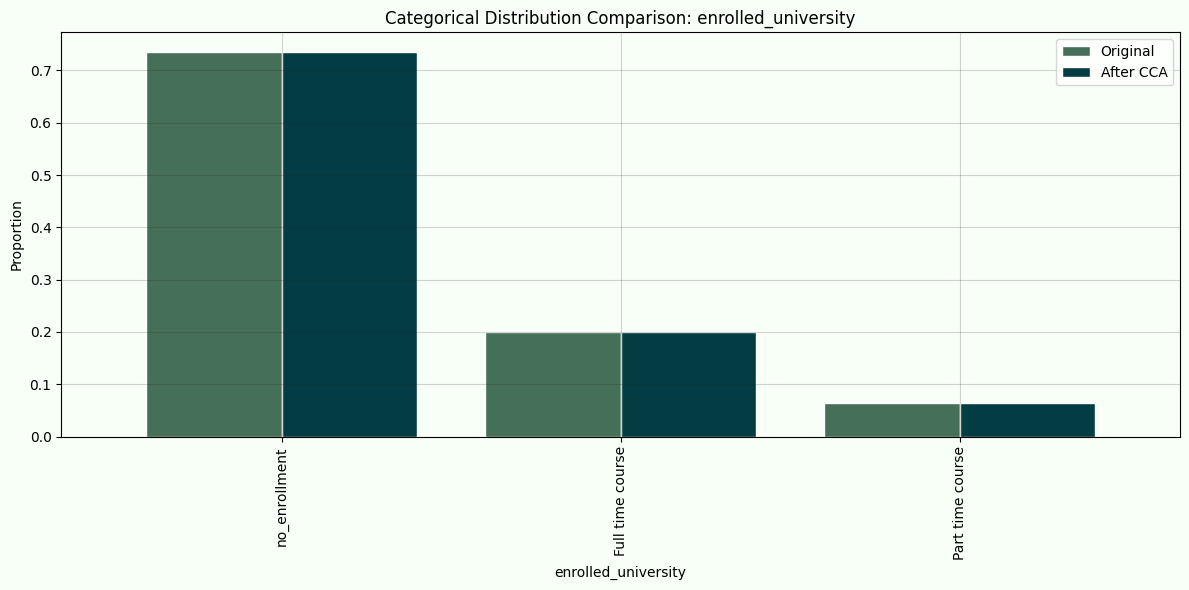

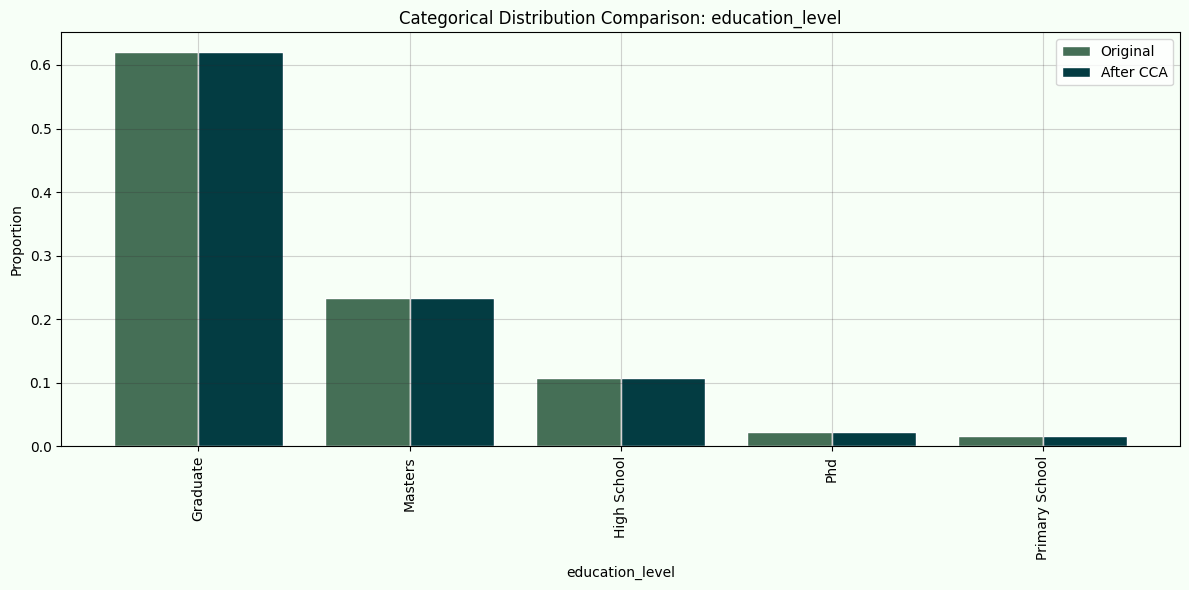

In [127]:

bg_color   = '#f7fff7'
grid_color = '#33202a'

for col in new_df.columns:
    # Only categorical columns
    if pd.api.types.is_numeric_dtype(df[col]):
        continue
    
    # 1. Relative frequencies
    df_counts     = df[col].value_counts(normalize=True).rename('Original')
    new_df_counts = new_df[col].value_counts(normalize=True).rename('After CCA')
    
    # 2. Combine for plotting
    df_compare = pd.concat([df_counts, new_df_counts], axis=1).fillna(0)
    
    # 3. Plot grouped bar chart
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.set_facecolor(bg_color)
    fig.set_facecolor(bg_color)
    
    df_compare.plot(
        kind='bar',
        ax=ax,
        color=['#456F56', '#033c42'],
        edgecolor='white',
        width=0.8
    )
    
    ax.set_title(f'Categorical Distribution Comparison: {col}')
    ax.set_ylabel('Proportion')
    ax.set_xlabel(col)
    ax.grid(True,color=grid_color, alpha=0.2)
    ax.legend()
    
    plt.tight_layout()
    plt.show()

In [128]:
col = missing_cols[0]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : city_development_index


,original,cca
city_development_index,,
0.920,0.265059,0.277733
0.624,0.136705,0.137760
0.910,0.078401,0.081364
0.926,0.067700,0.069200
0.698,0.034659,0.033058
...,...,...
0.649,0.000209,0.000175
0.807,0.000209,0.000233
0.781,0.000157,0.000175


In [129]:
col = missing_cols[1]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : enrolled_university


,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [130]:
col = missing_cols[2]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : education_level


,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
